# Polarimetric Vegetation Analysis with PolSARtools
<br>

This notebook introduces radar vegetation analysis using NISAR quad-polarization GSLC (Geocoded Single-Look Complex) products and [polSARtools](https://polsartools.readthedocs.io). Using `polSARtools`, this notebooks demonstrates how to:

- create C3 covariance and T3 coherency matrices
- apply a Refined Lee speckle filter
- calculate the Radar Vegetation Index (RVI)
- calculate the Polarimetric Radar Vegetation Index (PRVI)
- calculate the Generalized Volume Based Radar Vegetation Index (GRVI)
- display the vegetation indices on an interactive map

This example uses NISAR GSLC products, which provide geocoded complex SAR imagery suitable for polarimetric analysis and other advanced SAR applications. For more information on NISAR GSLC data, refer to the [NISAR Data User Guide](https://nisar-docs.asf.alaska.edu/gslc/). 

## Overview

1. [Prerequisites](veg_polsar-prereqs)
1. [Search and Download Data](veg_polsar-searchdownload)
1. [Create a Subset for High Resolution Processing](veg_polsar-subset)
1. [Create a C3 Covariance Matrix and/or a T3 Coherency Matrix](veg_polsar_c3t3)
1. [Reduce Speckle with a Refined Lee Filter](veg_polsar-filter)
1. [Create a Radar Vegetation Index](veg_polsar-rvi)
1. [Create a Polarimetric Radar Vegetation Index](veg_polsar-prvi)
1. [Create a Generalized Volume Based Radar Vegetation Index](veg_polsaar-grvi)
1. [Visualize the Vegetation Indices on an Interactive Map](veg_polsar-map)
1. [Summary](veg_polsar-summary)
1. [Resources and references](veg_polsar-references)

<hr>

(veg_polsar-prereqs)=
## 1. Prerequisites

| Prerequisite | Importance | Notes |
| --- | --- | --- |
| [The `isce3` software environment for this cookbook](software_environment_docker.ipynb) | Necessary | |
| [How to search and access NISAR data in your {abbr}`AOI (area of interest)`](search_download_NISAR_GCOV_asf_search.ipynb) | Helpful | |
| [Familiarity with polSARtools](https://polsartools.readthedocs.io/en/latest/index.html) | Helpful | |
| General knowledge of polarimetry | Helpful |

- **Rough Notebook Time Estimate**: 12 mins 

<hr>

(veg_polsar-searchdownload)=
## 2. Search and Download Dara

Use `asf_search` to find NISAR data. 

### 2a. Search for Data and Identify an Area of Interest (AOI)

In [1]:
import os
import asf_search as asf
from datetime import datetime
from getpass import getpass

import warnings
warnings.filterwarnings(
    "ignore",
    message="Parsing dates involving a day of month without a year specified",
)

# Option 1: Use Earthdata Login credentials stored in a .netrc file
session = asf.ASFSession()

# Option 2: Uncomment if needed: Enter your NASA Earthdata Login credentials
#session.auth_with_creds(input('EDL Username'), getpass('EDL Password'))

start_date = datetime(2026, 7, 3)
end_date = datetime(2026, 7, 5)

area_of_interest = "POLYGON((-147.7503 64.8584,-147.7131 64.8584,-147.7131 64.8719,-147.7503 64.8719,-147.7503 64.8584))" # Creamer's field

pattern = r'^(?!.*QA_STATS).*'

opts=asf.ASFSearchOptions(**{
    "maxResults": 250,
    "intersectsWith": area_of_interest,
    "flightDirection": "DESCENDING",
    "start": start_date,
    "end": end_date,
    "processingLevel": ["GSLC"],
    "dataset": ["NISAR"],
    "productionConfiguration": ["PR"],
    "dataMaturity" : "PROVISIONAL",
    'session': session,
})

response = asf.search(opts=opts)
hdf5_urls = response.find_urls(extension='.h5', pattern=pattern, directAccess=False)
print(f"Found {len(hdf5_urls)} GSLC products:")
hdf5_urls

Found 1 GSLC products:


['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GSLC_PROVISIONAL_V1/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001.h5']

### 2b. Retain only the URL for the most recent version of each product in the search results

Data is occasionally re-released with an updated version. Versions are recorded as a [Composite Release Identifier (CRID)](https://nisar-docs.asf.alaska.edu/naming-conventions/) in a product's filename. We can use the CRID to retain only the most recent version of each product in the list of URLs.

In [2]:
import re

if len(hdf5_urls) == 1:
    print("Single GSLC product found. Skipping CRID filter.")
    
else:
    pattern = re.compile(
        r"(NISAR_L2_PR_GSLC.*?)_[A-Z]([0-9]{5})_N_F_J_[0-9]{3}\.h5$"
    )

    latest_version_dict = {}

    for url in hdf5_urls:
        fname = url.split("/")[-1]

        match = pattern.search(fname)

        if not match:
            print(f"No match: {fname}")
            continue

        product, crid = match.groups()

        if (
            product not in latest_version_dict
            or crid > latest_version_dict[product][0]
        ):
            latest_version_dict[product] = (crid, url)

    hdf5_urls = [item[1] for item in latest_version_dict.values()]

print(f"Retained {len(hdf5_urls)} GSLC products:")
hdf5_urls

Single GSLC product found. Skipping CRID filter.
Retained 1 GSLC products:


['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GSLC_PROVISIONAL_V1/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001.h5']

## 2c. Download the Data

In [3]:
from pathlib import Path

# Create a folder and download the files
data_dir = Path.home() / "polSAR_veg_data"
data_dir.mkdir(exist_ok=True)
print(f'data_dir: {data_dir}')

#download files
asf.download_urls(hdf5_urls, data_dir, session=session, processes=4)

data_dir: /home/jovyan/polSAR_veg_data


In [4]:
gslc_files = sorted(data_dir.glob("*.h5"))
gslc_files

[PosixPath('/home/jovyan/polSAR_veg_data/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001.h5')]

In [5]:
in_file = str(gslc_files[0])

(veg_polsar-subset)=
## 3. Create a Subset for High Resolution Processing

The full-scene workflow provides an efficient way to process large GSLC products. When a smaller area of interest is sufficient, creating a spatial subset allows the data to be processed at a higher spatial resolution without extending processing times and storage requirements. 

`polsartools` expects a standard NISAR GSLC HDF5 product as input. Therefore, the subset is created by preserving the original HDF5 structure and metadata while clipping the datasets to the selected area of interest.

In [6]:
%%time 

from util.subset_h5 import subset_h5

area_of_interest = "POLYGON((-147.7503 64.8584,-147.7131 64.8584,-147.7131 64.8719,-147.7503 64.8719,-147.7503 64.8584))" # Creamer's field in Fairbanks, AK

subset_file = subset_h5(
    in_file,
    area_of_interest,
)

print(subset_file)

/home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset.h5
CPU times: user 270 ms, sys: 301 ms, total: 571 ms
Wall time: 571 ms


(veg_polsar_c3t3)=
## 4. Create a C3 Covariance Matrix and/or a T3 Coherency Matrix

The **C3 covariance matrix** and **T3 coherency matrix** are two different ways of representing information contained in full-polarimetric SAR measurements. They contain the same underlying polarimetric information, but arrange the information differently for different types of analysis.

- **C3:** describes the strength of the polarization returns and how the HH, HV, and VV measurements vary. It is useful for analyses that work directly with the relationships between the measured polarization channels, including polarimetric indices such as the Radar Vegetation Index (RVI).

- **T3:** transforms the polarization measurements into combinations that help describe the type of scattering occurring within a pixel. It is commonly used for analyses that distinguish or characterize scattering behaviors, including polarimetric decompositions and parameters such as entropy and alpha.

`PolSARtools` can generate either matrix directly from a full-polarimetric NISAR GSLC product. The appropriate matrix depends on the analysis being performed; many PolSARtools functions accept a C3 or T3 matrix as their input. We use both examples in this notebook.

:::{dropdown} Which matrix should I use? 
In general, consider a C3 when your analysis explores the strength of each polarization channel (HH, HV, VV), for example, when comparing the cross-pol (HV) return to the co-pol (HH and VV) returns. Consider a T3 when your analysis depends on identifying the type of scattering, such as surface, double bounce, or volume scattering. In this notebook, the RVI and PRVI can be calculated from either matrix, while the GRVI uses T3 because it compares each pixel to models of volume scattering.
:::

### 4.1 Create a C3 Matrix

The **C3 covariance matrix** describes the strength of and relationships between the full-polarimetric radar returns. The diagonal elements represent the strength of different polarization components and the off-diagonal elements describe relationships between those components.

:::{dropdown} More about constructing a C3 covariance matrix
The C3 covariance matrix has the following structure:

$$
\mathbf{C}_3 =
\begin{bmatrix}
C_{11} & C_{12} & C_{13} \\
C_{12}^{*} & C_{22} & C_{23} \\
C_{13}^{*} & C_{23}^{*} & C_{33}
\end{bmatrix}
$$

The **diagonal elements** ($C_{11}$, $C_{22}$, and $C_{33}$) describe the strength of the polarization components, while the **off-diagonal elements** describe the relationships between them. The $^{*}$ indicates the complex conjugate of the corresponding element.

The C3 matrix can also be viewed in terms of the polarization combinations used to form it. Below, each C3 element shows either the strength of an individual polarization component or the relationship between two polarization components. The lower off-diagonal elements are complex conjugates of the corresponding upper elements.

:::{math}
\mathbf{C}_3 =
\left[
\begin{array}{ccc}
\color{green}\langle HH\,HH^* \rangle
  & \langle HH\,HV^* \rangle
  & \langle HH\,VV^* \rangle
\\[6pt]
{\color{lightgray}\langle HV\,HH^* \rangle}
  & \color{green}\langle HV\,HV^* \rangle
  & \langle HV\,VV^* \rangle
\\[6pt]
{\color{lightgray}\langle VV\,HH^* \rangle}
  & {\color{lightgray}\langle VV\,HV^* \rangle}
  & \color{green}\langle VV\,VV^* \rangle
\end{array}
\right]
\\[12pt]
\textcolor{black}{\text{Black}}:\ \text{Off-diagonal covariance terms}\\
\textcolor{green}{\text{Green}}:\ \text{Diagonal terms}\\
\textcolor{lightgray}{\text{Light gray}}:\ \text{Complex conjugates of the corresponding off-diagonal terms}
:::


:::{dropdown} A note on NISAR products and C3 matrices: 

A potential alternative to generating a C3 matrix from a NISAR GSLC is to use the provided polarimetric covariance terms from a [NISAR GCOV](https://nisar-docs.asf.alaska.edu/gcov/) product. Note that the GCOV covariance data have undergone radiometric terrain correction (RTC).

Creating the C3 matrix directly from a GSLC with `PolSARtools` provides more control over processing choices such as multilooking and filtering. However, PolSARtools does not apply NISAR's radiometric terrain correction (RTC) when creating the matrix. If RTC is an important part of your analysis, consider using a GCOV product or manually creating a C3 matrix.

:::

In [7]:
import polsartools as pst 

gslc_subset = str(subset_file)

pst.import_nisar_gslc(
    gslc_subset,
    mat="C3",
    azlks=2,
    rglks=2,
    fmt="tif",
    cog=False,
    ovr=[2, 4, 8, 16],
    comp=False,
    recip=False
)

Detected L-band polarization channels: ['HH' 'HV' 'VH' 'VV']
Extracting C3 matrix elements...


Processing chunks: 100%|██████████| 1/1 [00:00<00:00, 28.29it/s]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/C3/C11.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/C3/C12_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/C3/C12_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/C3/C13_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/C3/C13_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/C3/C22.tif
Saved file /home/jovyan/polSAR_veg_dat

In [8]:
# PolSARtools saves the C3 elements in a "C3" folder next to the input file
C3_folder = os.path.join(os.path.splitext(gslc_subset)[0], "C3")

### 4.2 Extract the T3 Coherency Matrix
The **T3 coherency matrix** contains the same polarimetric information as the C3 matrix but organizes it using combinations that emphasize different scattering characteristics. This makes the T3 matrix particularly useful for polarimetric decompositions and scattering-based analyses.

:::{dropdown} More about constructing a T3 coherency matrix: 
The T3 coherency matrix has the following structure:


$$
\mathbf{T}_3 =
\begin{bmatrix}
T_{11} & T_{12} & T_{13} \\
T_{12}^{*} & T_{22} & T_{23} \\
T_{13}^{*} & T_{23}^{*} & T_{33}
\end{bmatrix}
$$


The **diagonal elements** ($T_{11}$, $T_{22}$, and $T_{33}$) describe the strength of the scattering components, while the **off-diagonal elements** describe the relationships between them. The $^*$ indicates the complex conjugate of the corresponding element.

The T3 matrix can also be viewed in terms of the polarization combinations used to form it. Below, the T3 elements are derived from the scattering vector **k**, which combines the HH, HV, and VV polarization measurements into components that emphasize different scattering characteristics. Each component of k is associated with a scattering type: k₁ (HH+VV) with surface scattering, k₂ (HH−VV) with double bounce scattering, and k₃ (HV) with volume scattering, such as from vegetation canopies.

:::{math}
\mathbf{T}_3 =
\left[
\begin{array}{ccc}
\color{green}\langle k_1 k_1^* \rangle
  & \langle k_1 k_2^* \rangle
  & \langle k_1 k_3^* \rangle
\\[6pt]
{\color{lightgray}\langle k_2 k_1^* \rangle}
  & \color{green}\langle k_2 k_2^* \rangle
  & \langle k_2 k_3^* \rangle
\\[6pt]
{\color{lightgray}\langle k_3 k_1^* \rangle}
  & {\color{lightgray}\langle k_3 k_2^* \rangle}
  & \color{green}\langle k_3 k_3^* \rangle
\end{array}
\right]

\qquad
\mathbf{k} =
\frac{1}{\sqrt{2}}
\begin{bmatrix}
HH+VV\\
HH-VV\\
2HV
\end{bmatrix}
:::

In [9]:
gslc_subset = str(subset_file)

pst.import_nisar_gslc(
    gslc_subset,
    mat="T3",
    azlks=2,
    rglks=2,
    fmt="tif",
    cog=False,
    ovr=[2, 4, 8, 16],
    comp=False,
    recip=False
)

Detected L-band polarization channels: ['HH' 'HV' 'VH' 'VV']
Extracting T3 matrix elements...


Processing chunks: 100%|██████████| 1/1 [00:00<00:00, 32.54it/s]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/T3/T11.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/T3/T12_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/T3/T12_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/T3/T13_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/T3/T13_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/T3/T22.tif
Saved file /home/jovyan/polSAR_veg_dat

In [10]:
# PolSARtools saves the T3 elements in a "T3" folder next to the input file
T3_folder = os.path.join(os.path.splitext(gslc_subset)[0], "T3")

(veg_polsar-filter)=
## 5. Reduce Speckle with a Refined Lee Filter 
Before calculating the vegetation indices, apply the [Refined Lee filter](https://ieeexplore.ieee.org/document/7334965) to reduce speckle while preserving important scattering features such as edges and boundaries. The implementation used by `polsSARtools` applies the same filter to all covariance terms, which is important for preserving the relationships between them while maintaining the ability to make relative comparisons between terms.

Here, we will need to apply the filter to both the C3 and T3 matrices. 

:::{dropdown} More about the Refined Lee Filter
The Refined Lee filter reduces speckle by analyzing the statistical properties of pixels in a local neighborhood. Rather than applying a fixed level of smoothing, it adjusts amounts of smoothing based on local image characteristics. The Refined Lee filter applies more smoothing in homogeneous areas while preserving edges, boundaries, and other important scattering features.
:::

### 5.1: Apply Refined Lee Filter to C3 Matrix

In [11]:
window_size = 3

pst.filter_refined_lee(
    C3_folder,
    win=window_size,
    fmt="tif",
    sub_dir=True,
    cog=False,
    ovr=[2, 4, 8, 16],
    comp=False
)

# The filtered C3 elements are saved in a new subfolder
C3_filtered_folder = os.path.join(os.path.splitext(gslc_subset)[0], f"rlee_{window_size}x{window_size}", "C3")

Progress: 100%|██████████| 1/1 [00:00<00:00, 15.81block/s]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/C11.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/C12_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/C12_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/C13_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/C13_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee

### 5.2: Apply Refined Lee Filter to T3 Matrix

In [12]:
window_size = 3

pst.filter_refined_lee(
    T3_folder,
    win=window_size,
    fmt="tif",
    sub_dir=True,
    cog=False,
    ovr=[2, 4, 8, 16],
    comp=False
)

# The filtered T3 elements are saved in a new subfolder
T3_filtered_folder = os.path.join(os.path.splitext(gslc_subset)[0], f"rlee_{window_size}x{window_size}", "T3")

Progress: 100%|██████████| 1/1 [00:00<00:00, 15.68block/s]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/T3/T11.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/T3/T12_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/T3/T12_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/T3/T13_real.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/T3/T13_imag.tif
Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee

(veg_polsar-rvi)=
## 6. Create a Radar Vegetation Index

The Radar Vegetation Index (RVI) is one of the most widely used radar indices for monitoring vegetation. In simple terms, it measures how randomly the radar signal is scattered within each pixel. Bare ground tends to scatter the signal in a simple, organized way, while leaves and branches scatter it more randomly. `PolSARtools` calculates the RVI from the eigenvalues of the C3 coherency matrix:

$$
RVI = \frac{4\,\lambda_3}{\lambda_1 + \lambda_2 + \lambda_3}
$$

where $\lambda_1$, $\lambda_2$, and $\lambda_3$ are the eigenvalues of C3 in descending order. Values range from about 0 to 1, with values near 0 indicating bare surfaces and values near 1 indicating dense vegetation.

The RVI is useful because it is simple to interpret and works well for tracking vegetation growth, such as changes in crops over a season. However, it can saturate in dense vegetation and can be affected by surface roughness and viewing angle, which is part of why newer indices, such as the PRVI and GRVI, were developed.

In [13]:
# Calculate the RVI from the filtered C3 matrix
pst.rvi_fp(
    C3_filtered_folder,
    win=1,
    fmt="tif",
    cog=True,
    block_size=(1024, 1024)
)

Progress: 100%|██████████| 1/1 [00:00<00:00, 13.77block/s]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/rvifp.tif
Execution time for rvi_fp: 0.00 seconds


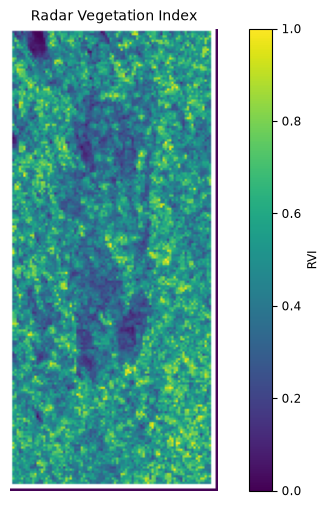

In [14]:
import rasterio 
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Load and plot the RVI
rvi_file = os.path.join(C3_filtered_folder, "rvifp.tif")

with rasterio.open(rvi_file) as src:
    rvi = src.read(1, masked=True)

plt.figure(figsize=(8, 6))
im = plt.imshow(rvi, vmin=0, vmax=1)
plt.colorbar(im, label="RVI")
plt.title("Radar Vegetation Index")
plt.axis("off")
plt.show()

(veg_polsar-prvi)=
## 7. Create a Polarimetric Radar Vegetation Index

The Polarimetric Radar Vegetation Index (PRVI) is used to estimate how much vegetation is present. It combines the cross-pol backscatter, which increases with vegetation, with the degree of polarization (DOP), which decreases as vegetation scatters the radar signal more randomly:

$$
\mathrm{PRVI}_{fp} = \left(1 - \mathrm{DOP}_{fp}\right)\sigma^\circ_{XY}
$$

where $\sigma^\circ_{XY}$ is the cross-pol (HV) backscatter and $\mathrm{DOP}_{fp}$ is the 3D Barakat degree of polarization:

$$
\mathrm{DOP}_{fp} = \sqrt{1 - \frac{27 \times \det([\mathrm{T3}])}{\left(\mathrm{Trace}[\mathrm{T3}]\right)^3}}
$$

Combining these two measurements makes the PRVI less sensitive to bare soil, surface roughness, and viewing angle than HV backscatter or the RVI alone. This makes the PRVI especially useful in sparsely vegetated areas such as shrublands. For more details, see [Chang et al. (2018)](https://ieeexplore.ieee.org/document/8402138).

:::{dropdown} Interpreting the PRVI

Higher PRVI values (brighter colors) indicate more vegetation. These areas return a strong cross-pol signal and scatter the radar randomly, which is typical of forests, shrublands, and dense crops. Lower values (darker colors) indicate little or no vegetation, such as bare soil, rock, and calm water, which return a weak cross-pol signal and a highly polarized response.

Potential sources of error:

- PRVI values are relative as the PRVI has no fixed range
- Urban areas can appear bright due to ue building angles that produce a strong cross-pol return that appears like vegetation 
- These results do not have terrain correction. Slopes can appear brighter or darker than they should 

Both the PRVI and RVI highlight the same vegetated areas, but the PRVI often shows more contrast in sparsely vegetated regions.
:::

In [15]:
# Calculate the PRVI from the filtered C3 matrix
pst.prvi_fp(
    C3_filtered_folder,
    win=1,
    fmt="tif",
    cog=True,
    block_size=(1024, 1024)
)

Progress: 100%|██████████| 1/1 [00:00<00:00, 48.72block/s]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/C3/prvi_fp.tif
Execution time for prvi_fp: 0.00 seconds


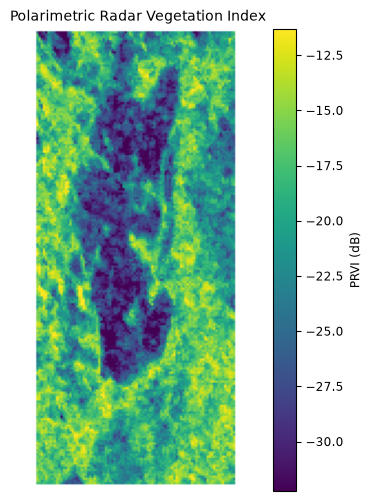

In [16]:
# Load and plot the PRVI
prvi_file = os.path.join(C3_filtered_folder, "prvi_fp.tif")

with rasterio.open(prvi_file) as src:
    prvi = src.read(1, masked=True)

# Convert the PRVI to decibels (dB) to improve contrast between low and high values
prvi_db = 10 * np.log10(prvi)

# Use only valid pixels to set the color range
valid = prvi_db[np.isfinite(prvi_db)]

plt.figure(figsize=(8, 6))
im = plt.imshow(prvi_db, vmin=np.percentile(valid, 2), vmax=np.percentile(valid, 98))
plt.colorbar(im, label="PRVI (dB)")
plt.title("Polarimetric Radar Vegetation Index")
plt.axis("off")
plt.show()

(veg_polsaar-grvi)=
## 8. Create a Generalized Volume Based Radar Vegetation Index

The Generalized Volume Based Radar Vegetation Index (GRVI) estimates vegetation by comparing the scattering in each pixel to a model of how vegetation scatters radar. In theory, pixels that look similar to vegetation scattering receive high values, while pixels that look like simple targets, such as bare ground or buildings, receive low values:

$$
\mathrm{GRVI} = \left(1 - \mathrm{GD}_{\mathrm{GV}}\right)\left(\frac{p}{q}\right)^{2\,\mathrm{GD}_{\mathrm{GV}}}, \quad 0 \le \mathrm{GRVI} \le 1
$$

where $\mathrm{GD}_{\mathrm{GV}}$ is the geodesic distance between the Kennaugh ($\mathbf{K}$) matrices of the observed and the generalized volume scattering model, and $p$ and $q$ are the minimum and maximum distances between the $\mathbf{K}$ matrices of the observed and elementary targets.

Because the GRVI uses the full polarimetric information rather than just the strength of the HV return, it can separate vegetation from other surfaces that also produce strong cross-pol returns. It is also less sensitive to noise than the RVI, which depends on the smallest eigenvalue and can be affected by noise in the data.

The GRVI was developed for crop monitoring and tested on spring wheat and soybean fields in Manitoba, Canada, using C-band RADARSAT-2 data. In that study, it was more strongly related to plant area and vegetation water content than the RVI. Since NISAR uses L-band, which penetrates deeper into vegetation, results may differ, especially in forests and shrublands. For more details, see [Ratha et al. (2019)](https://ieeexplore.ieee.org/document/8695778).

::: {dropdown} More about Kennaugh Matrices
The Kennaugh matrix is a 4×4 real-valued matrix that contains the same polarimetric information as the C3 and T3 matrices, but expressed in terms of scattered power. Because it contains only real numbers, two Kennaugh matrices can be compared directly using the geodesic distance, which ranges from 0 (identical scattering) to 1 (completely different scattering). The GRVI uses this distance to compare each pixel to a vegetation scattering model and to simple reference targets such as surfaces and double bounce scatterers.
:::

In [17]:
# Calculate the GRVI from the filtered T3 matrix
pst.grvi(
    T3_filtered_folder,
    win=1,
    fmt="tif",
    cog=True,
    block_size=(1024, 1024)
)

Progress: 100%|██████████| 1/1 [00:06<00:00,  6.12s/block]

Saved file /home/jovyan/polSAR_veg_data/subset/NISAR_L2_PR_GSLC_024_116_D_055_2005_QPDH_A_20260704T055929_20260704T060006_P05023_N_F_J_001_subset/rlee_3x3/T3/grvi.tif
Execution time for grvi: 6.00 seconds


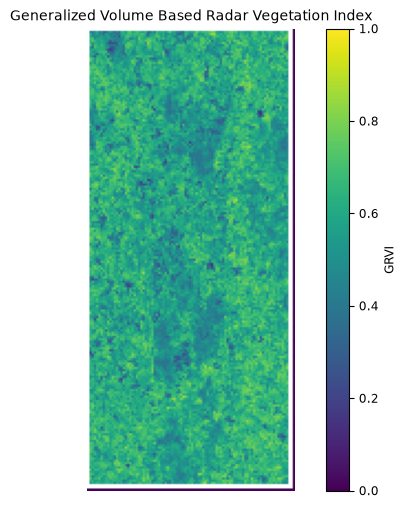

In [18]:
# Load and plot the GRVI
grvi_file = os.path.join(T3_filtered_folder, "grvi.tif")

with rasterio.open(grvi_file) as src:
    grvi = src.read(1, masked=True)

plt.figure(figsize=(8, 6))
im = plt.imshow(grvi, vmin=0, vmax=1)
plt.colorbar(im, label="GRVI")
plt.title("Generalized Volume Based Radar Vegetation Index")
plt.axis("off")
plt.show()

(veg_polsar-map)=
## 9. Visualize the Vegetation Indices on an Interactive Map

To see how the vegetation indices relate to the landscape, we overlay the RVI, PRVI, and GRVI on a basemap. Use the layer control in the upper right corner to switch between indices and compare them with the satellite imagery.

<br>

In [19]:
import folium
from rasterio.vrt import WarpedVRT

def index_overlay(tif_path, vmin, vmax):
    with rasterio.open(tif_path) as src, WarpedVRT(src, crs="EPSG:4326", nodata=np.nan) as vrt:
        data = vrt.read(1, masked=True)
        west, south, east, north = vrt.bounds

    colored = plt.cm.viridis((data - vmin) / (vmax - vmin))
    return colored, [[south, west], [north, east]]

# For PVRI, convert to db
def index_overlay_db(tif_path, vmin, vmax):
    with rasterio.open(tif_path) as src, WarpedVRT(src, crs="EPSG:4326", nodata=np.nan) as vrt:
        data = 10 * np.log10(vrt.read(1, masked=True))
        west, south, east, north = vrt.bounds

    colored = plt.cm.viridis((data - vmin) / (vmax - vmin))
    return colored, [[south, west], [north, east]]


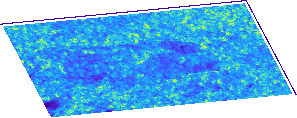
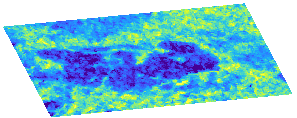
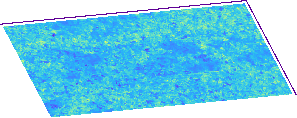

In [20]:
# Color each index (the PRVI is shown in dB using its 2nd and 98th percentiles)
rvi_img, bounds = index_overlay(rvi_file, 0, 1)
grvi_img, _ = index_overlay(grvi_file, 0, 1)
prvi_img, _ = index_overlay_db(prvi_file, *np.percentile(valid, [2, 98]))

m = folium.Map(tiles="Esri.WorldImagery")

folium.raster_layers.ImageOverlay(rvi_img, bounds, name="RVI", opacity=0.8).add_to(m)
folium.raster_layers.ImageOverlay(prvi_img, bounds, name="PRVI (dB)", opacity=0.8, show=False).add_to(m)
folium.raster_layers.ImageOverlay(grvi_img, bounds, name="GRVI", opacity=0.8, show=False).add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds(bounds)
m

(veg_polsar-summary)=
## 10. Summary

You have now learned how to use `polSARtools` to estimate vegetation from full-polarimetric NISAR GSLC data. This workflow demonstrated how to create the C3 covariance and T3 coherency matrices, reduce speckle with the Refined Lee filter, and calculate three radar vegetation indices:

- **Radar Vegetation Index (RVI):** a simple, widely used measure of how randomly the radar signal is scattered.
- **Polarimetric Radar Vegetation Index (PRVI):** combines the cross-pol (HV) backscatter with the degree of polarization
- **Generalized Volume Based Radar Vegetation Index (GRVI):** compares each pixel to a model of vegetation scattering

Finally, the indices were visualized on an interactive map to compare results with surrounding landscapes. 
<br>


(veg_polsar-references)=
## 11. Resources and References

- [polsartools](https://polsartools.readthedocs.io)
- [polSARtools: Functions](https://polsartools.readthedocs.io/en/latest/files/02functions.html)
- [polsartools: NISAR GSLC Full-Pol Tutorial](https://github.com/polsartools/polsartools-tutorials/blob/main/jupyter-notebooks/NISAR_GSLC_Full_pol.ipynb)
- [NISAR Data User Guide](YOUR_EXISTING_LINK)

Publications: 

- Kim, Y., & van Zyl, J. J. (2009). [A time-series approach to estimate soil moisture using polarimetric radar data](https://ieeexplore.ieee.org/document/4810143). *IEEE Transactions on Geoscience and Remote Sensing*, 47(8), 2519–2527.
- Chang, J. G., Shoshany, M., & Oh, Y. (2018). [Polarimetric Radar Vegetation Index for Biomass Estimation in Desert Fringe Ecosystems](https://ieeexplore.ieee.org/document/8402138). *IEEE Transactions on Geoscience and Remote Sensing*, 56(12), 7102–7108.
- Ratha, D., Mandal, D., Kumar, V., McNairn, H., Bhattacharya, A., & Frery, A. C. (2019). [A Generalized Volume Scattering Model-Based Vegetation Index From Polarimetric SAR Data](https://ieeexplore.ieee.org/document/8695778). *IEEE Geoscience and Remote Sensing Letters*, 16(11), 1791–1795.

**Author:** Julia White 